# Day 3 — NumPy arrays and Pandas DataFrames

Run each cell with **Shift + Enter**, from the top. Every example uses the student data from Day 2.

## 1. Introduction to NumPy arrays

In [ ]:
import numpy as np

# 1D array: the five students' exam scores
scores = np.array([35, 45, 55, 65, 75])
print(scores)

# 2D array (a matrix): study hours, attendance and exam score for each student
data = np.array([[1, 60, 35],
                 [2, 70, 45],
                 [3, 80, 55],
                 [4, 90, 65],
                 [5, 95, 75]])
print(data)

# Arrays of zeros and ones
print(np.zeros((2, 3)))
print(np.ones((2, 3)))

[35 45 55 65 75]
[[ 1 60 35]
 [ 2 70 45]
 [ 3 80 55]
 [ 4 90 65]
 [ 5 95 75]]
[[0. 0. 0.]
 [0. 0. 0.]]
[[1. 1. 1.]
 [1. 1. 1.]]


In [ ]:
# Shape, dimensions, data type and size
print("Shape:", data.shape)
print("Dimensions:", data.ndim)
print("Data type:", data.dtype)
print("Number of elements:", data.size)

Shape: (5, 3)
Dimensions: 2
Data type: int64
Number of elements: 15


In [ ]:
# Indexing and slicing: [row, column], counting from 0
print(data[0, 2])       # first student's exam score
print(data[1])          # second student's row
print(data[:, 2])       # the exam score column
print(data[1:3, 0:2])   # students 2-3: hours and attendance

35
[ 2 70 45]
[35 45 55 65 75]
[[ 2 70]
 [ 3 80]]


In [ ]:
# Vectorized operations: one line works on every element, no loop
hours = data[:, 0]
print("Scores + 5 bonus points:", scores + 5)
print("Study minutes:", hours * 60)
print("Mean score:", np.mean(scores))
print("Total hours:", np.sum(hours))
print("Standard deviation:", np.std(scores))
print("Sample standard deviation:", np.std(scores, ddof=1))

Scores + 5 bonus points: [40 50 60 70 80]
Study minutes: [ 60 120 180 240 300]
Mean score: 55.0
Total hours: 15
Standard deviation: 14.142135623730951
Sample standard deviation: 15.811388300841896


## 2. Array operations and vectorization

In [ ]:
# Element-wise arithmetic: each exam score with the same student's previous score
exam = np.array([35, 45, 55, 65, 75])
previous = np.array([40, 50, 60, 70, 80])

print("exam + previous:", exam + previous)
print("exam - previous:", exam - previous)    # the change since the previous test
print("exam * 2:       ", exam * 2)
print("exam / previous:", (exam / previous).round(2))

exam + previous: [ 75  95 115 135 155]
exam - previous: [-5 -5 -5 -5 -5]
exam * 2:        [ 70  90 110 130 150]
exam / previous: [0.88 0.9  0.92 0.93 0.94]


In [ ]:
# Broadcasting: NumPy stretches a smaller array to match a bigger one, when the shapes allow it
bonus = np.array([0, 0, 5])          # one value per column: +5 on the exam score only
print(data.shape, bonus.shape)
print(data + bonus)

# Shapes are compared from the right: each pair of sizes must be equal, or one of them 1
for other in [np.zeros(3), np.zeros((5, 1)), np.zeros(5), np.zeros(2)]:
    try:
        print(data.shape, "+", other.shape, "->", (data + other).shape)
    except ValueError:
        print(data.shape, "+", other.shape, "-> error: shapes don't match")

(5, 3) (3,)
[[ 1 60 40]
 [ 2 70 50]
 [ 3 80 60]
 [ 4 90 70]
 [ 5 95 80]]
(5, 3) + (3,) -> (5, 3)
(5, 3) + (5, 1) -> (5, 3)
(5, 3) + (5,) -> error: shapes don't match
(5, 3) + (2,) -> error: shapes don't match


In [ ]:
# Useful NumPy functions, on the exam scores
print("Sum:", np.sum(exam))
print("Mean:", np.mean(exam))
print("Median:", np.median(exam))
print("Standard deviation:", np.std(exam).round(2))
print("Minimum:", np.min(exam))
print("Maximum:", np.max(exam))

Sum: 275
Mean: 55.0
Median: 55.0
Standard deviation: 14.14
Minimum: 35
Maximum: 75


In [ ]:
# Get the dataset: Colab starts with an empty folder, so download the file the first time
import os
import urllib.request

URL = "https://raw.githubusercontent.com/neerajb1/learnforge-notebooks/main/ai-ml-120/day-003/data/student_data.csv"
if not os.path.exists("student_data.csv"):
    urllib.request.urlretrieve(URL, "student_data.csv")

In [ ]:
import pandas as pd

# The student dataset's columns as NumPy arrays
df = pd.read_csv("student_data.csv")
hours = df["StudyHours"].to_numpy()
scores = df["ExamScore"].to_numpy()

print("Average study hours:", np.mean(hours))
print("Average exam score:", np.mean(scores))
print("Points per study hour:", (scores / hours).round(1))

Average study hours: 3.0
Average exam score: 55.0
Points per study hour: [35.  22.5 18.3 16.2 15. ]


In [ ]:
# Performance: add up a million numbers with a Python loop, then with NumPy
import timeit

numbers = np.arange(1_000_000)

def python_loop():
    total = 0
    for x in numbers:
        total += x
    return total

loop_ms = min(timeit.repeat(python_loop, number=1, repeat=3)) * 1000
numpy_ms = min(timeit.repeat(lambda: np.sum(numbers), number=1, repeat=3)) * 1000

print("Same answer:", python_loop() == np.sum(numbers))
print(f"Python loop: {loop_ms:.1f} ms")
print(f"NumPy sum:   {numpy_ms:.2f} ms")
print(f"NumPy was about {loop_ms / numpy_ms:.0f} times faster")

Same answer: True
Python loop: 40.4 ms
NumPy sum:   0.29 ms
NumPy was about 142 times faster


## 3. Pandas DataFrames basics

In [ ]:
import pandas as pd

# Create a DataFrame from a dictionary: the same students as Day 2
data = {
    "Student": ["S1", "S2", "S3", "S4", "S5"],
    "StudyHours": [1, 2, 3, 4, 5],
    "Attendance": [60, 70, 80, 90, 95],
    "ExamScore": [35, 45, 55, 65, 75],
}
df = pd.DataFrame(data)
print(df)

  Student  StudyHours  Attendance  ExamScore
0      S1           1          60         35
1      S2           2          70         45
2      S3           3          80         55
3      S4           4          90         65
4      S5           5          95         75


In [ ]:
# Load the same student dataset from the CSV file (it also has PreviousScore and Passed)
df = pd.read_csv("student_data.csv")
print(df.head())

  Student  StudyHours  Attendance  PreviousScore  ExamScore  Passed
0      S1           1          60             40         35   False
1      S2           2          70             50         45   False
2      S3           3          80             60         55    True
3      S4           4          90             70         65    True
4      S5           5          95             80         75    True


In [ ]:
# Inspect the DataFrame
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
print("\nData types:")
print(df.dtypes)
print()
df.info()          # info() prints its own report
print()
print(df.describe())

Shape: (5, 6)
Columns: ['Student', 'StudyHours', 'Attendance', 'PreviousScore', 'ExamScore', 'Passed']

Data types:
Student          object
StudyHours        int64
Attendance        int64
PreviousScore     int64
ExamScore         int64
Passed             bool
dtype: object

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   Student        5 non-null      object
 1   StudyHours     5 non-null      int64 
 2   Attendance     5 non-null      int64 
 3   PreviousScore  5 non-null      int64 
 4   ExamScore      5 non-null      int64 
 5   Passed         5 non-null      bool  
dtypes: bool(1), int64(4), object(1)
memory usage: 337.0+ bytes

       StudyHours  Attendance  PreviousScore  ExamScore
count    5.000000    5.000000       5.000000   5.000000
mean     3.000000   79.000000      60.000000  55.000000
std      1.581139   14.317821      15.811388  15

In [ ]:
# Select a single column (a Series)
print(df["ExamScore"])

# Select multiple columns
print(df[["Student", "ExamScore"]])

# Select the first 3 rows
print(df.head(3))

# Select rows using a condition
print(df[df["ExamScore"] > 60])

0    35
1    45
2    55
3    65
4    75
Name: ExamScore, dtype: int64
  Student  ExamScore
0      S1         35
1      S2         45
2      S3         55
3      S4         65
4      S5         75
  Student  StudyHours  Attendance  PreviousScore  ExamScore  Passed
0      S1           1          60             40         35   False
1      S2           2          70             50         45   False
2      S3           3          80             60         55    True
  Student  StudyHours  Attendance  PreviousScore  ExamScore  Passed
3      S4           4          90             70         65    True
4      S5           5          95             80         75    True


## 4. Loading and exploring data with Pandas

In [ ]:
import pandas as pd

# Load the student dataset and view the first rows
df = pd.read_csv("student_data.csv")
print(df.head())

  Student  StudyHours  Attendance  PreviousScore  ExamScore  Passed
0      S1           1          60             40         35   False
1      S2           2          70             50         45   False
2      S3           3          80             60         55    True
3      S4           4          90             70         65    True
4      S5           5          95             80         75    True


In [ ]:
# Shape: rows and columns
print("Shape:", df.shape)

Shape: (5, 6)


In [ ]:
# Column names
print("Columns:", df.columns.tolist())

Columns: ['Student', 'StudyHours', 'Attendance', 'PreviousScore', 'ExamScore', 'Passed']


In [ ]:
# The data type of each column
print(df.dtypes)

Student          object
StudyHours        int64
Attendance        int64
PreviousScore     int64
ExamScore         int64
Passed             bool
dtype: object


In [ ]:
# A summary of the DataFrame (info() prints its own report)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   Student        5 non-null      object
 1   StudyHours     5 non-null      int64 
 2   Attendance     5 non-null      int64 
 3   PreviousScore  5 non-null      int64 
 4   ExamScore      5 non-null      int64 
 5   Passed         5 non-null      bool  
dtypes: bool(1), int64(4), object(1)
memory usage: 337.0+ bytes


In [ ]:
# Summary statistics for the numeric columns
print(df.describe())

       StudyHours  Attendance  PreviousScore  ExamScore
count    5.000000    5.000000       5.000000   5.000000
mean     3.000000   79.000000      60.000000  55.000000
std      1.581139   14.317821      15.811388  15.811388
min      1.000000   60.000000      40.000000  35.000000
25%      2.000000   70.000000      50.000000  45.000000
50%      3.000000   80.000000      60.000000  55.000000
75%      4.000000   90.000000      70.000000  65.000000
max      5.000000   95.000000      80.000000  75.000000


In [ ]:
# Count the missing values in each column
print(df.isnull().sum())

Student          0
StudyHours       0
Attendance       0
PreviousScore    0
ExamScore        0
Passed           0
dtype: int64


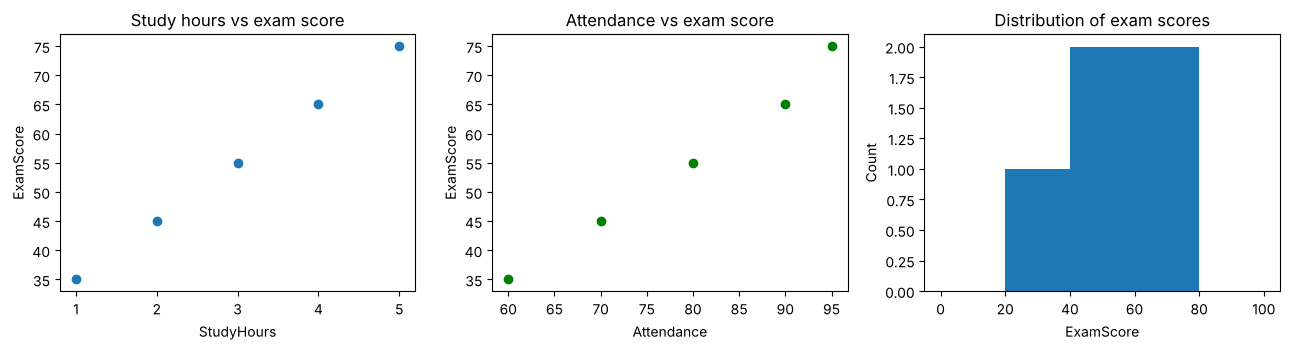

In [ ]:
import matplotlib.pyplot as plt

# Three charts of the same data
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
axes[0].scatter(df["StudyHours"], df["ExamScore"])
axes[0].set(title="Study hours vs exam score", xlabel="StudyHours", ylabel="ExamScore")
axes[1].scatter(df["Attendance"], df["ExamScore"], color="green")
axes[1].set(title="Attendance vs exam score", xlabel="Attendance", ylabel="ExamScore")
axes[2].hist(df["ExamScore"], bins=[0, 20, 40, 60, 80, 100])
axes[2].set(title="Distribution of exam scores", xlabel="ExamScore", ylabel="Count")
plt.tight_layout()
plt.show()

In [ ]:
# Quick insights: how closely each column moves with the exam score (from -1 to 1)
print(df[["StudyHours", "Attendance"]].corrwith(df["ExamScore"]).round(2))
print("Students scoring 40-80:", df["ExamScore"].between(40, 80).sum(), "of", len(df))

StudyHours    1.00
Attendance    0.99
dtype: float64
Students scoring 40-80: 4 of 5


## 5. Filtering and selecting data

In [ ]:
# Select a single column
print(df["ExamScore"])

# Select multiple columns
print(df[["Student", "StudyHours", "ExamScore"]])

0    35
1    45
2    55
3    65
4    75
Name: ExamScore, dtype: int64
  Student  StudyHours  ExamScore
0      S1           1         35
1      S2           2         45
2      S3           3         55
3      S4           4         65
4      S5           5         75


In [ ]:
# Students with an exam score greater than 60
print(df[df["ExamScore"] > 60])

# Students with attendance of 80 or more
print(df[df["Attendance"] >= 80])

  Student  StudyHours  Attendance  PreviousScore  ExamScore  Passed
3      S4           4          90             70         65    True
4      S5           5          95             80         75    True
  Student  StudyHours  Attendance  PreviousScore  ExamScore  Passed
2      S3           3          80             60         55    True
3      S4           4          90             70         65    True
4      S5           5          95             80         75    True


In [ ]:
# AND (&): a score above 60 and attendance of at least 80
print(df[(df["ExamScore"] > 60) & (df["Attendance"] >= 80)])

# OR (|): studied only 1 hour, or scored above 70
print(df[(df["StudyHours"] == 1) | (df["ExamScore"] > 70)])

  Student  StudyHours  Attendance  PreviousScore  ExamScore  Passed
3      S4           4          90             70         65    True
4      S5           5          95             80         75    True
  Student  StudyHours  Attendance  PreviousScore  ExamScore  Passed
0      S1           1          60             40         35   False
4      S5           5          95             80         75    True


In [ ]:
# isin(): rows whose value is in a list
print(df[df["Student"].isin(["S1", "S3", "S5"])])

  Student  StudyHours  Attendance  PreviousScore  ExamScore  Passed
0      S1           1          60             40         35   False
2      S3           3          80             60         55    True
4      S5           5          95             80         75    True


In [ ]:
# query(): the AND filter above, written as a readable string
print(df.query("ExamScore > 60 and Attendance >= 80"))

# Both ways give exactly the same rows
boolean = df[(df["ExamScore"] > 60) & (df["Attendance"] >= 80)]
print(boolean.equals(df.query("ExamScore > 60 and Attendance >= 80")))

  Student  StudyHours  Attendance  PreviousScore  ExamScore  Passed
3      S4           4          90             70         65    True
4      S5           5          95             80         75    True
True


In [ ]:
# Sort by exam score, highest first
print(df.sort_values("ExamScore", ascending=False))

# Sort by attendance, lowest first
print(df.sort_values("Attendance")[["Student", "Attendance"]])

  Student  StudyHours  Attendance  PreviousScore  ExamScore  Passed
4      S5           5          95             80         75    True
3      S4           4          90             70         65    True
2      S3           3          80             60         55    True
1      S2           2          70             50         45   False
0      S1           1          60             40         35   False
  Student  Attendance
0      S1          60
1      S2          70
2      S3          80
3      S4          90
4      S5          95


In [ ]:
# .iloc[] selects by position: rows 0, 1 and 2 (the end, 3, is left out)
print(df.iloc[0:3])

# .iloc[] rows 1-3, and columns 0, 1 and 4
print(df.iloc[1:4, [0, 1, 4]])

# .loc[] selects by label. Use the Student names as row labels:
by_name = df.set_index("Student")
print(by_name.loc["S3"])

# A label slice includes its end: S2, S3 and S4
print(by_name.loc["S2":"S4", ["StudyHours", "ExamScore"]])

  Student  StudyHours  Attendance  PreviousScore  ExamScore  Passed
0      S1           1          60             40         35   False
1      S2           2          70             50         45   False
2      S3           3          80             60         55    True
  Student  StudyHours  ExamScore
1      S2           2         45
2      S3           3         55
3      S4           4         65
StudyHours          3
Attendance         80
PreviousScore      60
ExamScore          55
Passed           True
Name: S3, dtype: object
         StudyHours  ExamScore
Student                       
S2                2         45
S3                3         55
S4                4         65


## 6. Practice and mini project: student performance analysis

In [ ]:
import numpy as np
import pandas as pd

# 1. Load and prepare the data
df = pd.read_csv("student_data.csv")
print(df.head())
print("\nShape:", df.shape)
print("Columns:", df.columns.tolist())
print("\nData types:")
print(df.dtypes)

  Student  StudyHours  Attendance  PreviousScore  ExamScore  Passed
0      S1           1          60             40         35   False
1      S2           2          70             50         45   False
2      S3           3          80             60         55    True
3      S4           4          90             70         65    True
4      S5           5          95             80         75    True

Shape: (5, 6)
Columns: ['Student', 'StudyHours', 'Attendance', 'PreviousScore', 'ExamScore', 'Passed']

Data types:
Student          object
StudyHours        int64
Attendance        int64
PreviousScore     int64
ExamScore         int64
Passed             bool
dtype: object


In [ ]:
# 2. Clean and verify: missing values, duplicates, then summary statistics
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print()
print(df.describe().round(1))

Missing values: 0
Duplicate rows: 0

       StudyHours  Attendance  PreviousScore  ExamScore
count         5.0         5.0            5.0        5.0
mean          3.0        79.0           60.0       55.0
std           1.6        14.3           15.8       15.8
min           1.0        60.0           40.0       35.0
25%           2.0        70.0           50.0       45.0
50%           3.0        80.0           60.0       55.0
75%           4.0        90.0           70.0       65.0
max           5.0        95.0           80.0       75.0


In [ ]:
# High performers: an exam score above 60
print(df[df["ExamScore"] > 60][["Student", "StudyHours", "ExamScore"]])

  Student  StudyHours  ExamScore
3      S4           4         65
4      S5           5         75


In [ ]:
# Low performers: an exam score below 50
print(df[df["ExamScore"] < 50][["Student", "StudyHours", "ExamScore"]])

  Student  StudyHours  ExamScore
0      S1           1         35
1      S2           2         45


In [ ]:
# Study time: average hours of the students who passed, and who didn't
print("Passed:", df.loc[df["Passed"], "StudyHours"].mean())
print("Not passed:", df.loc[~df["Passed"], "StudyHours"].mean())

Passed: 4.0
Not passed: 1.5


In [ ]:
# Attendance: students with attendance of 80 or more, and their average score
good = df[df["Attendance"] >= 80]
print(good[["Student", "Attendance", "ExamScore"]])
print("Average score:", good["ExamScore"].mean())

  Student  Attendance  ExamScore
2      S3          80         55
3      S4          90         65
4      S5          95         75
Average score: 65.0


Try the questions yourself first, then run this cell to check.

In [ ]:
# Mini project answers, with NumPy for the calculations
scores = df["ExamScore"].to_numpy()
hours = df["StudyHours"].to_numpy()
low = df["Attendance"].to_numpy() < 80

print("1. Average exam score:", np.mean(scores))
print("2. Correlation of study hours and score:", np.corrcoef(hours, scores)[0, 1].round(2))
print("3. Top 3 by exam score:", df.nlargest(3, "ExamScore")["Student"].tolist())
print("4. Average score with attendance below 80:", scores[low].mean(), "| 80 or more:", scores[~low].mean())
print("5. Pass rate:", f"{df['Passed'].mean():.0%}")

1. Average exam score: 55.0
2. Correlation of study hours and score: 1.0
3. Top 3 by exam score: ['S5', 'S4', 'S3']
4. Average score with attendance below 80: 40.0 | 80 or more: 65.0
5. Pass rate: 60%


## Your turn

- Change a score in the NumPy array and re-run the cells.
- Filter the students with attendance of 80% or more.
- Add a column of your own to the DataFrame.